In [4]:
import ee
import os
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

ee.Initialize()

# Denmark HOBE Network Area
BBOX = [8.8, 55.8, 9.4, 56.1] 
START_DATE = "2017-01-01"
END_DATE   = "2018-12-31"
AOI = ee.Geometry.Rectangle(BBOX)
PATCH_SIZE = 13

In [5]:
def load_ismn(file_path):
    with open(file_path, 'r') as f:
        header = f.readline().strip().split()
    try:
        network, station = header[1], header[2]
        lat, lon = float(header[3]), float(header[4])
    except:
        return None

    df = pd.read_csv(file_path, sep=r'\s+', skiprows=1, header=None, engine='python')
    if df.shape[1] < 4: return None
    
    df = df.iloc[:, :4]
    df.columns = ['date', 'time', 'sm', 'flag']
    df = df[df['flag'] == 'G'] # Only 'Good' quality
    
    df['timestamp'] = pd.to_datetime(df['date'] + ' ' + df['time'])
    df['sm'] = pd.to_numeric(df['sm'], errors='coerce')
    df = df.dropna(subset=['sm'])

    # HOBE often reports in % (0-50+); convert to m3/m3 (0-0.5+)
    if df['sm'].mean() > 1.0:
        df['sm'] = df['sm'] / 100.0

    df['point_id'] = f"{network}_{station}"
    df['latitude'] = lat
    df['longitude'] = lon
    return df[['point_id', 'timestamp', 'sm', 'latitude', 'longitude']]

# Execution
stm_files = glob.glob('Data/Denmark/HOBE/*/*.stm', recursive=True)
dfs = [load_ismn(f) for f in stm_files if load_ismn(f) is not None]
ground_truth = pd.concat(dfs, ignore_index=True)

# Daily Floor
ground_truth['timestamp'] = ground_truth['timestamp'].dt.floor('D')
ground_truth = ground_truth.groupby(['point_id','timestamp','latitude','longitude'], as_index=False)['sm'].mean()

In [6]:
def get_s2(aoi, start, end):
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(aoi).filterDate(start, end)
    def add_idx(img):
        ndvi = img.normalizedDifference(['B8','B4']).rename('NDVI')
        ndwi = img.normalizedDifference(['B8','B11']).rename('NDWI')
        return ee.Image.cat([ndvi, ndwi]).copyProperties(img, ['system:time_start'])
    return s2.map(add_idx)

def get_s1(aoi, start, end):
    s1 = ee.ImageCollection('COPERNICUS/S1_GRD') \
        .filterBounds(aoi) \
        .filterDate(start, end) \
        .filter(ee.Filter.eq('instrumentMode', 'IW')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarization', 'VV')) \
        .filter(ee.Filter.listContains('transmitterReceiverPolarization', 'VH'))

    def proc_s1(img):
        # Now we are 100% sure VV and VH exist
        ratio = img.select('VV').divide(img.select('VH').add(0.0001)).rename('VV_VH_Ratio')
        return img.select(['VV', 'VH']).addBands(ratio).copyProperties(img, ['system:time_start'])
    
    return s1.map(proc_s1)

def get_lst(aoi, start, end):
    return ee.ImageCollection('MODIS/061/MOD11A1').filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select('LST_Day_1km').multiply(0.02).subtract(273.15)
               .rename('LST').copyProperties(img, ['system:time_start']))

def get_smap(aoi, start, end):
    return ee.ImageCollection('NASA/SMAP/SPL4SMGP/008').filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select('sm_surface').rename('SMAP').copyProperties(img, ['system:time_start']))

def get_era5_plus(aoi, start, end):
    col = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").filterBounds(aoi).filterDate(start, end)
    def proc(img):
        return ee.Image.cat([
            img.select("volumetric_soil_water_layer_1").rename("ERA5_SM"),
            img.select("total_precipitation_sum").rename("precip"),
            img.select("surface_net_solar_radiation_sum").rename("ssr"),
            img.select("temperature_2m").subtract(273.15).rename("T_air"),
            img.select("dewpoint_temperature_2m").subtract(273.15).rename("Td_air")
        ]).copyProperties(img, ["system:time_start"])
    return col.map(proc)

def get_lai(aoi, start, end):
    return ee.ImageCollection("MODIS/061/MCD15A3H").filterBounds(aoi).filterDate(start, end) \
        .map(lambda img: img.select("Lai").multiply(0.1).rename("LAI").copyProperties(img, ['system:time_start']))

def get_topo():
    dem = ee.Image("NASA/NASADEM_HGT/001").select('elevation')
    slope = ee.Terrain.slope(dem).rename('slope')
    aspect = ee.Terrain.aspect(dem).rename('aspect')
    return ee.Image.cat([dem.rename('elevation'), slope, aspect])

def get_soil():
    return ee.Image.cat([
        ee.Image("projects/soilgrids-isric/clay_mean").select("clay_0-5cm_mean").rename("clay"),
        ee.Image("projects/soilgrids-isric/sand_mean").select("sand_0-5cm_mean").rename("sand"),
        ee.Image("projects/soilgrids-isric/silt_mean").select("silt_0-5cm_mean").rename("silt")
    ])

# Safety helper functions
def get_daily_safe(col, date, bands):
    next_day = ee.Date(date).advance(1, 'day')
    subset = col.filterDate(date, next_day)
    empty = ee.Image.constant([0] * len(bands)).rename(bands).selfMask()
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_window_safe(col, date, bands, days=30):
    window_start = ee.Date(date).advance(-days, 'day')
    subset = col.filterDate(window_start, ee.Date(date).advance(1, 'day'))
    empty = ee.Image.constant([0] * len(bands)).rename(bands).selfMask()
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_daily_no_mask(col, date, bands):
    next_day = ee.Date(date).advance(1, 'day')
    subset = col.filterDate(date, next_day)
    # Instead of selfMask(), we provide a constant 0. 
    # This ensures the pixel always "exists" so sampleRegions won't drop it.
    empty = ee.Image.constant([0] * len(bands)).rename(bands)
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def get_window_no_mask(col, date, bands, days=30):
    window_start = ee.Date(date).advance(-days, 'day')
    subset = col.filterDate(window_start, ee.Date(date).advance(1, 'day'))
    empty = ee.Image.constant([0] * len(bands)).rename(bands)
    return ee.Image(ee.Algorithms.If(subset.size().gt(0), subset.median().select(bands), empty))

def build_spatial_stack(date, s2, s1, lst, smap, era5, lai, soil, topo):
    date = ee.Date(date)
    
    # Standard Point Stack
    img = ee.Image.cat([
        get_window_no_mask(s2, date, ['NDVI', 'NDWI']).unmask(0),
        get_window_no_mask(lai, date, ['LAI']).unmask(0),
        get_window_no_mask(s1, date, ['VV','VH','VV_VH_Ratio'], days=12).unmask(0),
        get_daily_no_mask(lst, date, ['LST']).unmask(0),
        get_daily_safe(era5, date, ['ERA5_SM','precip','ssr','T_air']).unmask(0),
        get_daily_safe(smap, date, ['SMAP']).unmask(0),
        soil,
        topo
    ])
    
    # CONVERT TO SPATIAL PATCHES
    # neighborhoodToArray creates a [PATCH_SIZE x PATCH_SIZE] array for every band
    kernel = ee.Kernel.square(radius=(PATCH_SIZE - 1) // 2, units='pixels')
    spatial_img = img.neighborhoodToArray(kernel)
    
    return spatial_img.set('system:time_start', date.millis())

# %% THE BUILDER
def build_daily_final(date, s2, s1, lst, smap, era5, lai, soil, topo):
    date = ee.Date(date)
    
    # We use unmask() to ensure that if a pixel is cloudy, 
    # it returns 0 instead of 'null'. This prevents row-dropping.
    img = ee.Image.cat([
        get_window_no_mask(s2, date, ['NDVI', 'NDWI']).unmask(0),
        get_window_no_mask(lai, date, ['LAI']).unmask(0),
        get_window_no_mask(s1, date, ['VV','VH','VV_VH_Ratio'], days=12).unmask(0),
        get_daily_no_mask(lst, date, ['LST']).unmask(0),
        get_daily_safe(era5, date, ['ERA5_SM','precip','ssr','T_air','Td_air']).unmask(0),
        get_daily_safe(smap, date, ['SMAP']).unmask(0),
        soil,
        topo
    ])
    
    return img.set('system:time_start', date.millis())

# %% EXECUTION

# 1. Setup Collections once
BUFFER_START = ee.Date(START_DATE).advance(-30, 'day')
s2_col = get_s2(AOI, BUFFER_START, END_DATE)
s1_col = get_s1(AOI, BUFFER_START, END_DATE)
lai_col = get_lai(AOI, BUFFER_START, END_DATE)
lst_col = get_lst(AOI, START_DATE, END_DATE)
smap_col = get_smap(AOI, START_DATE, END_DATE)
era5_col = get_era5_plus(AOI, START_DATE, END_DATE)
soil_img = get_soil()
topo_img = get_topo()

# 2. Date Sequence
dates = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'day').subtract(1)).map(
    lambda d: ee.Date(START_DATE).advance(d, 'day')
)



# 4. Point Collection
points = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([r.longitude, r.latitude]), {'point_id': r.point_id})
    for r in ground_truth[['point_id','longitude','latitude']].drop_duplicates().itertuples()
])


spatial_collection = ee.ImageCollection(
    dates.map(lambda d: build_spatial_stack(d, s2_col, s1_col, lst_col, smap_col, era5_col, lai_col, soil_img, topo_img))
)

def sample_patches(img):
    ts = img.get('system:time_start')
    return img.sampleRegions(
        collection=points, 
        properties=['point_id'], 
        scale=1000, # 1km pixels
        tileScale=8
    ).map(lambda f: f.set('timestamp', ts))

# Exporting as TFRecord is mandatory for these array-based features
training_patches = spatial_collection.map(sample_patches).flatten()
all_feature_names = [
    'point_id', 'timestamp', 
    'NDVI', 'NDWI', 'LAI', 
    'VV', 'VH', 'VV_VH_Ratio', 
    'LST', 'ERA5_SM', 'precip', 'ssr', 'T_air', 
    'SMAP', 'clay', 'sand', 'silt',
    'elevation', 'slope', 'aspect'
]

task = ee.batch.Export.table.toDrive(
    collection=training_patches,
    description='HOBE_Spatial_Patches_13x13',
    fileFormat='TFRecord',
    selectors=all_feature_names  
)
#task.start()
print("Spatial Export Task Started. Monitor in GEE Task Manager.")

Spatial Export Task Started. Monitor in GEE Task Manager.


In [7]:
# %% 3. FEATURE ENGINEERING & MERGING
# Assuming you already have the 'HOBE_feature.csv' from your GEE export
df_feat = pd.read_csv('Data/Denmark/HOBE_feature.csv')
df_feat['timestamp'] = pd.to_datetime(df_feat['timestamp'], unit='ms').dt.floor('D')

df = pd.merge(ground_truth, df_feat, on=['point_id','timestamp'], how='left')

# --- Brutal Feature Engineering ---
df = df.sort_values(['point_id', 'timestamp'])

# 1. Radar Ratio
df['VV_VH_Ratio'] = df['VV'] / (df['VH'] + 1e-6)

# 2. Cumulative Precipitation (7-day is better for Denmark's slow drainage)
df['precip_7d'] = df.groupby('point_id')['precip'].transform(lambda x: x.rolling(7).sum())

# 3. Seasonal Encoding (Prevents model from getting 'lost' in winter/summer)
df['day_of_year'] = df['timestamp'].dt.dayofyear
df['sin_day'] = np.sin(2 * np.pi * df['day_of_year'] / 365)
df['cos_day'] = np.cos(2 * np.pi * df['day_of_year'] / 365)

# 4. Cleanup
XGB_df = df.copy()
cols_to_nan = ['LST', 'NDVI', 'NDWI', 'LAI', 'VV', 'VH', 'VV_VH_Ratio']
XGB_df[cols_to_nan] = XGB_df[cols_to_nan].replace(0, np.nan)

# Target: The 'Delta' from the SMAP baseline
anchor = 'SMAP'
XGB_df['sm_delta'] = XGB_df['sm'] - XGB_df[anchor]
XGB_df = XGB_df.dropna(subset=['sm_delta', anchor])

In [8]:
features = [
    'SMAP', 'ERA5_SM', 'precip_7d', 'LST', 
    'VV_VH_Ratio', 'NDVI', 'NDWI', 'LAI',
    'sand', 'clay', 'elevation', 'T_air', 
    'sin_day', 'cos_day'
]

# Station-based split to ensure spatial generalization
stations = XGB_df['point_id'].unique()
np.random.seed(42)
np.random.shuffle(stations)
split = int(len(stations) * 0.8)

train_data = XGB_df[XGB_df['point_id'].isin(stations[:split])]
test_data = XGB_df[XGB_df['point_id'].isin(stations[split:])]

model = xgb.XGBRegressor(
    n_estimators=3000,
    max_depth=5,
    learning_rate=0.01,
    subsample=0.8,
    colsample_bytree=0.5,
    reg_lambda=25, # High L2 to keep it honest
    early_stopping_rounds=100,
    missing=np.nan,
    random_state=42
)

model.fit(
    train_data[features], train_data['sm_delta'],
    eval_set=[(test_data[features], test_data['sm_delta'])],
    verbose=False
)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.5
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_metho

In [9]:
preds_delta = model.predict(test_data[features])
final_preds = preds_delta + test_data[anchor].values
r2 = r2_score(test_data['sm'], final_preds)

print(f"--- Denmark XGBoost Point-Wise Baseline ---")
print(f"R2 Score: {r2:.4f}")
print("Feature Gains:", model.get_booster().get_score(importance_type='gain'))

--- Denmark XGBoost Point-Wise Baseline ---
R2 Score: 0.2471
Feature Gains: {'SMAP': 0.10105210542678833, 'ERA5_SM': 0.3905552625656128, 'precip_7d': 0.017004653811454773, 'LST': 0.01596594601869583, 'VV_VH_Ratio': 0.6277104020118713, 'NDVI': 0.10693063586950302, 'NDWI': 0.22844357788562775, 'LAI': 0.24256445467472076, 'sand': 0.47180044651031494, 'clay': 0.7627826929092407, 'elevation': 0.4990352690219879, 'T_air': 0.17412495613098145, 'sin_day': 0.0839996486902237, 'cos_day': 0.4449182152748108}


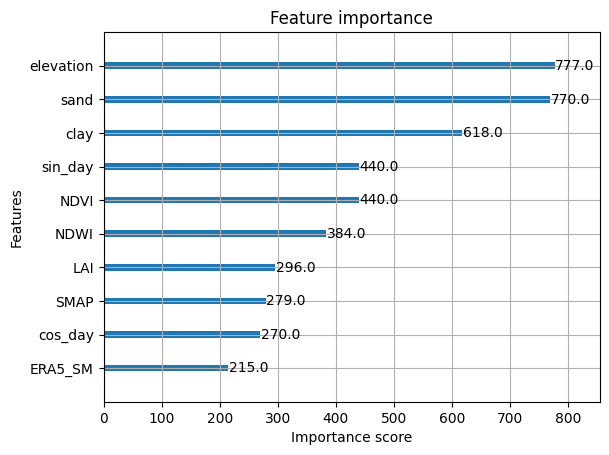

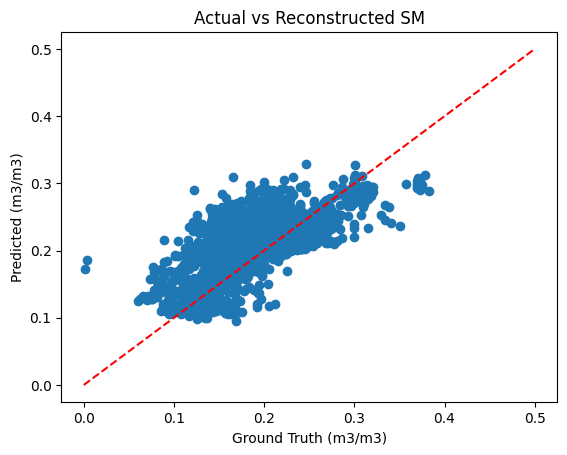

=== DATASET STRUCTURE ===
Total Rows: 12209
Unique Stations: 28

=== THE 'SM' SMOKING GUN (UNITS CHECK) ===
count    12209.000000
mean         0.215720
std          0.086229
min          0.001000
25%          0.156625
50%          0.212737
75%          0.269861
max          0.493571
Name: sm, dtype: float64

=== MISSING DATA (THE GAP CHECK) ===
system:index    | Nulls:    20 | Zeros:     0
ERA5_SM         | Nulls:    20 | Zeros:     0
LAI             | Nulls:    20 | Zeros:     2
LST             | Nulls:    20 | Zeros:  8356
NDVI            | Nulls:    20 | Zeros:  2878
NDWI            | Nulls:    20 | Zeros:  2878
SMAP            | Nulls:    20 | Zeros:     0
T_air           | Nulls:    20 | Zeros:     0
Td_air          | Nulls:    20 | Zeros:     0
VH              | Nulls:    20 | Zeros:     0
VV              | Nulls:    20 | Zeros:     0
VV_VH_Ratio     | Nulls:    20 | Zeros:     0
aspect          | Nulls:    20 | Zeros:   167
clay            | Nulls:    20 | Zeros:     0
elevation

In [10]:
import matplotlib.pyplot as plt
xgb.plot_importance(model, max_num_features=10)
plt.show()
import matplotlib.pyplot as plt
plt.scatter(test_data['sm'], final_preds)
plt.plot([0, 0.5], [0, 0.5], '--r')
plt.title("Actual vs Reconstructed SM")
plt.xlabel("Ground Truth (m3/m3)")
plt.ylabel("Predicted (m3/m3)")
plt.show()
import pandas as pd
import numpy as np

def run_brutal_diagnostics(df, target_col='sm'):
    print("=== DATASET STRUCTURE ===")
    print(f"Total Rows: {len(df)}")
    print(f"Unique Stations: {df['point_id'].nunique()}")
    
    print("\n=== THE 'SM' SMOKING GUN (UNITS CHECK) ===")
    # If max is < 0.01, the data is definitely scaled incorrectly
    print(df[target_col].describe())
    
    print("\n=== MISSING DATA (THE GAP CHECK) ===")
    nulls = df.isna().sum()
    zeros = (df == 0).sum()
    for col in df.columns:
        if nulls[col] > 0 or zeros[col] > 0:
            print(f"{col:15} | Nulls: {nulls[col]:5} | Zeros: {zeros[col]:5}")

    print("\n=== FEATURE ALIGNMENT (CORRELATION) ===")
    # Focus on the 'Big Three' - these MUST align
    numeric_df = df.select_dtypes(include=[np.number])
    if all(col in numeric_df.columns for col in [target_col, 'SMAP', 'ERA5_SM']):
        corrs = numeric_df.corr()[target_col].sort_values(ascending=False)
        print("Top 5 Positive Correlations:")
        print(corrs.head(6))
        print("\nTop 5 Negative Correlations:")
        print(corrs.tail(5))

    print("\n=== SPATIAL CONSISTENCY (STATION VARIANCE) ===")
    station_stats = df.groupby('point_id')[target_col].agg(['mean', 'std', 'count']).head(10)
    print("Sample of Station-wise Ground Truth stats:")
    print(station_stats)

    print("\n=== TEMPORAL ALIGNMENT ===")
    print(f"Date Range: {df['timestamp'].min()} to {df['timestamp'].max()}")
    
    # Check if SMAP and sm even move together at one station
    sample_station = df['point_id'].unique()[0]
    sample_df = df[df['point_id'] == sample_station].sort_values('timestamp').head(5)
    print(f"\nSample Time-Series Slice (Station: {sample_station}):")
    print(sample_df[['timestamp', target_col, 'SMAP', 'ERA5_SM']])

# Run it
run_brutal_diagnostics(df)
print(model.get_booster().get_score(importance_type='gain'))